# 12 · Drill into a JEPA fit

> **Engine-line study.** Notebooks 09–14 belong to the earlier latent-replenishment study on the full engine (`src/jepa/`, ADRs 0024–0032). Its published result, in `docs/jepa-replenishment.md` and `docs/paper/`, is that the latent planner did not beat a tuned order-up-to rule. The follow-up is the perfect-supplier line (notebook 15, ADR 0033).

This notebook runs the study's own functions on a **short** log and plots what they produce. It is not a second copy of the model. The published 896-episode, 365-tick run is the commands in the root README and the tables in `docs/jepa-replenishment.md`. That run is not repeated here.

Two comparisons get mixed together in the write-up:

- **Forecast gate.** `held_out_rollout_accuracy` compares the latent rollout with least squares (`fit_least_squares_dynamics`, rolled by `_ols_rollout`). On the published log the latent mean R² is 0.432 and least squares is −0.110, so the gate `rollout_beats_baseline` opens. On the separate 112-episode measurement log the same least-squares procedure scored about 0.36 and the latent model about 0.12. Least squares losing is a property of the 12-step linear rollout on the large log. It is not the buying comparison.
- **Buying comparison.** `compare_synthetic` scores `ReplenishmentPlanner.decide` against a tuned `OrderUpToPolicy`. On the training products at holding rate 0.01 that rule earns about 1.021 `net_profit / initial_cash`. The latent planner on the same seeds, in the holding-rate sweep, earns about 0.381. Its profits correlate with never-order at 0.9987.

The quantity `_score` searches is `round(cover × censored_rate × delivery_lag)` with `cover` in `COVERS = (0, 1, 2, 4)`. The rate is `_estimate_rate` on observed sales. The anchor adds `safety_lead_pct_of_lag` and, when `_has_stockout` is true, `stockout_safety_bonus_pct_of_lag`. The planner does not. The network changes which cover wins. It does not replace that formula.

Sections below:

1. Build the drill log with `collect_transition_log` and plot two episodes through `Runner` and the inspect frames.
2. Print the `LatentDynamics` modules `fit_latent` actually constructs.
3. Fit that model and plot the loss `LatentDynamics.fit` writes.
4. On each held-out episode, call `decide` for the logged buyer, the planner, and the tuned order-up-to rule on the **same** observation, then roll the planner and the anchor in closed loop the way `run_policy_episode` does.


In [1]:
import json
import os
from pathlib import Path

while not (Path.cwd() / "pyproject.toml").exists():
    os.chdir("..")

%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd

from src.jepa.commands import order_up_to_study_name, _order_up_to_factory
from src.jepa.dynamics import (
    ARRIVAL_AGE_SLOTS,
    PUBLISHED_DEPTH,
    PUBLISHED_EMBED_DIM,
    PUBLISHED_LR,
    SALES_WINDOW,
    feature_dim,
    log_row_features,
    parameter_count,
    target_dim,
    trainable_parameter_count,
)
from src.jepa.eval import IN_DISTRIBUTION_HOLDING_RATE
from src.jepa.log import (
    COLUMNS,
    LOG_SEED_OFFSET,
    OVER_ORDER_WEIGHT,
    _TransitionRecorder,
    _annotate_steps,
    _factory_overrides,
    _transitions,
    build_log_scenario,
    collect_transition_log,
    collection_config,
    log_buyer,
)
from src.jepa.plan import DEFAULT_BUDGET, fit_latent
from src.jepa.policy import COVERS
from src.sim.inspect import (
    flow_frame,
    global_timeseries_df,
    node_timeseries_df,
    per_product_df,
    purchase_frame,
)
from src.sim.node import FactoryNode
from src.sim.policy import IntermediatePolicy, _estimate_rate
from src.sim.runner import Runner
from src.tuning.episode import make_synthetic_catalog, partition_catalog
from src.tuning.rollout import run_policy_episode
from src.tuning.search_spaces import order_up_to_from_params

# Drill knobs. Published fit uses the same width, depth, learning rate, and
# budget, on 365-tick episodes with K and lag sampled and 64 episodes per arm.
DRILL_TICKS = 36
DRILL_SKUS = 2
DRILL_LAG = 3
DRILL_EPISODES_EACH = 1
DRILL_EPOCHS = 8
DRILL_SEED_OFFSET = LOG_SEED_OFFSET
ARTIFACT_DIR = Path("runs/jepa-drilldown/fit")

# Recorded best_params for holding rate 0.01 in docs/jepa-replenishment.md.
# Used only when the study file is absent. runs/ is gitignored.
PUBLISHED_ANCHOR_001 = {
    "cover_horizon_ticks": 12,
    "safety_lead_pct_of_lag": 0.16993287200409285,
    "stockout_safety_bonus_pct_of_lag": 0.09706576917593086,
}


## 1 · The training log

`collect_transition_log` is the collector. At `n_episodes_each=1` the schedule is still 14 episodes: one each of the four textbook arms, exploratory, and never-order, plus `OVER_ORDER_WEIGHT` (8) over-order episodes. Seeds start at `LOG_SEED_OFFSET`. The last tick of each episode is dropped inside `_transitions`, because it has no next row.

The catalog is rebuilt with `make_synthetic_catalog` and `partition_catalog`, which is what `collect_transition_log` does before `build_log_scenario`.


In [2]:
config = collection_config(
    episode_length=DRILL_TICKS,
    k_active=DRILL_SKUS,
    delivery_lag=DRILL_LAG,
    holding_rate=IN_DISTRIBUTION_HOLDING_RATE,
)
catalog, _evaluation = partition_catalog(make_synthetic_catalog(config.active_catalog_size()))
frame = collect_transition_log(
    n_episodes_each=DRILL_EPISODES_EACH,
    episode_length=DRILL_TICKS,
    k_active=DRILL_SKUS,
    delivery_lag=DRILL_LAG,
    seed_offset=DRILL_SEED_OFFSET,
)
print("rows", len(frame), "episodes", frame["episode_seed"].nunique())
print("over_order weight", OVER_ORDER_WEIGHT)
print(frame.groupby("behavior")["episode_seed"].nunique().rename("episodes"))
print("columns", list(frame.columns))


rows 980 episodes 14
over_order weight 8
behavior
exploratory             1
never_order             1
order_up_to             1
over_order              8
periodic_order_up_to    1
periodic_reorder        1
reorder_point           1
Name: episodes, dtype: int64
columns ['episode_seed', 'behavior', 'tick', 'product_id', 'on_hand', 'in_transit', 'sales_window', 'cash', 'capacity', 'requested_qty', 'filled_qty', 'delivery_lag', 'next_on_hand', 'next_in_transit', 'next_sales']


## 2 · One episode, tick by tick

`replay_collector_episode` is `_record_episode` in `src/jepa/log.py`, with the `Runner` log kept. The study function discards that log after `_annotate_steps` and `_transitions`. The charts read the log through `flow_frame`, `per_product_df`, `purchase_frame`, `node_timeseries_df`, and `global_timeseries_df`.

Factories are `StaticFactoryPolicy` via `_factory_overrides`, which is the collector's factory policy. Shop list price is `base_price` (`flow_frame` column `price` on node `S`). Supplier list price is the `FactoryNode.list_price` on the scenario. Sink demand is `flow_frame` on the `D_<pid>` node. The encoder never sees price, demand, or the market column.


seed 14000000 behavior order_up_to delivery_lag 3 hyper {'planning_depth': 14, 'cover_horizon_ticks': 14, 'safety_lead_pct_of_lag': 1.2843472895048618, 'stockout_safety_bonus_pct_of_lag': 1.3737485776131975}


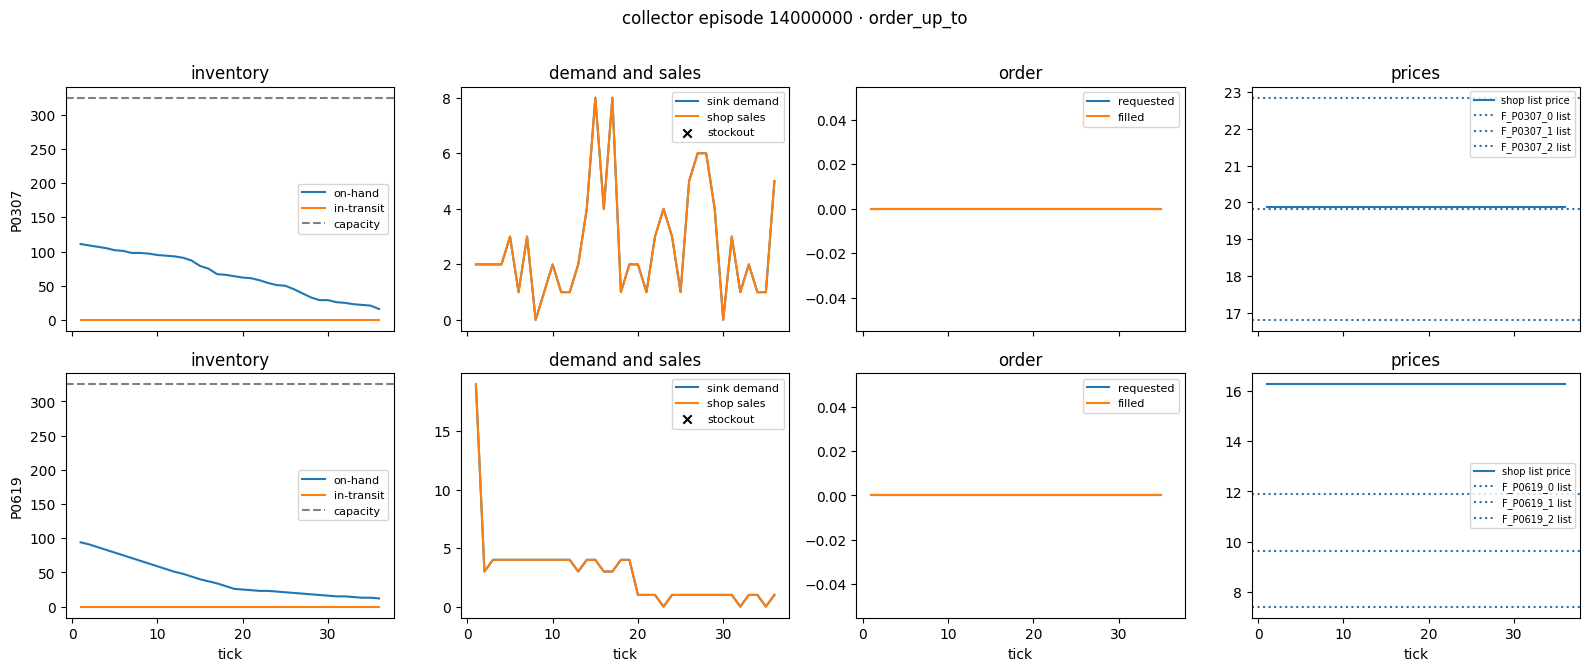

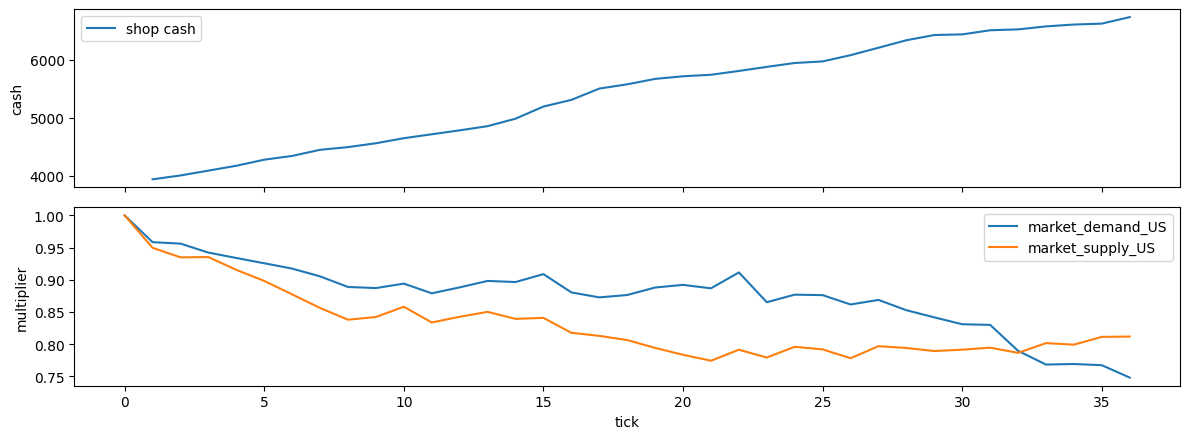

seed 14000006 behavior over_order delivery_lag 3 hyper {'planning_depth': 51}


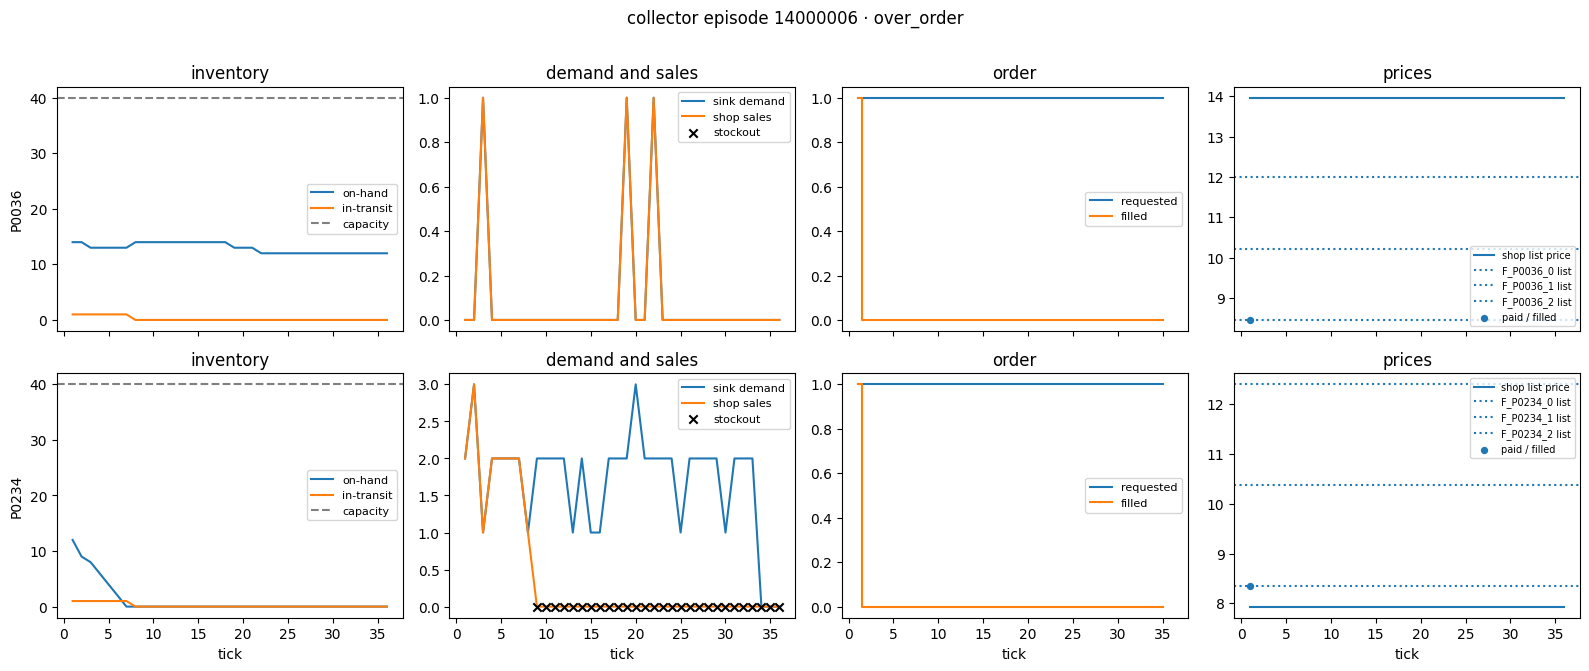

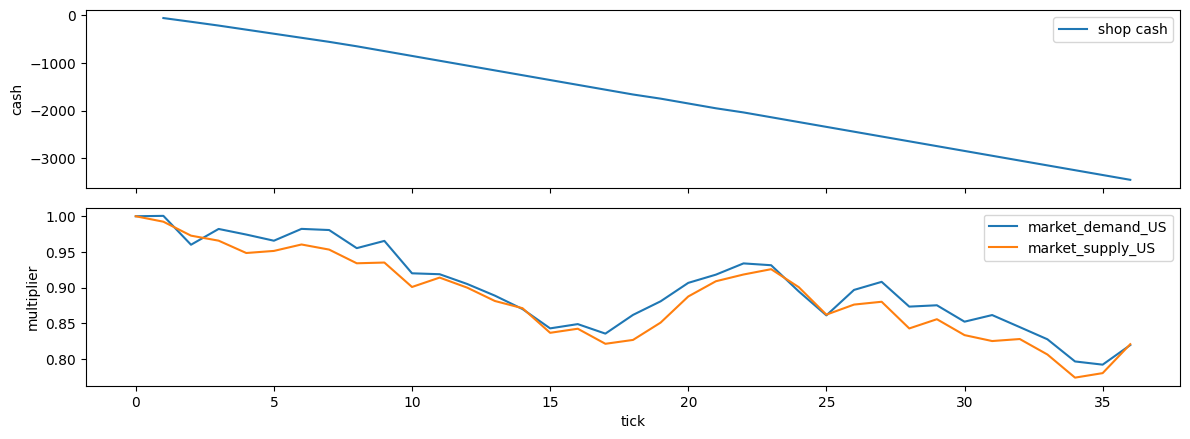

In [3]:
def order_units(action, pid):
    """Units requested for one SKU. Same sum as ``_snapshot``."""
    lines = (action.get("order") or {}).get(pid) or []
    return sum(int(qty) for _supplier, qty in lines)


def replay_collector_episode(seed):
    """Run one logged episode the way ``_record_episode`` does, and keep the run log."""
    seed = int(seed)
    behavior = frame.loc[frame["episode_seed"] == seed, "behavior"].iloc[0]
    spec = build_log_scenario(config, seed, catalog)
    buyer, hyper = log_buyer(behavior, seed, spec.delivery_lag)
    recorder = _TransitionRecorder(buyer)
    overrides = _factory_overrides(spec.scenario)
    overrides["S"] = recorder
    run_log = Runner(spec.scenario, policy_overrides=overrides).run()
    _annotate_steps(recorder.steps, run_log, spec.scenario, "S", spec.delivery_lag)
    rows = pd.DataFrame(
        _transitions(recorder.steps, seed, behavior, spec.delivery_lag),
        columns=list(COLUMNS),
    )
    return spec, behavior, hyper, run_log, rows


def _match_log(seed, rows):
    """The replay's transition rows are the rows ``collect_transition_log`` stored."""
    logged = (
        frame.loc[frame["episode_seed"] == int(seed)]
        .sort_values(["product_id", "tick"])
        .reset_index(drop=True)
    )
    fresh = rows.sort_values(["product_id", "tick"]).reset_index(drop=True)
    if len(logged) != len(fresh):
        raise AssertionError(f"replay row count {len(fresh)} != log {len(logged)} at seed {seed}")
    for column in ("on_hand", "requested_qty", "filled_qty", "next_sales"):
        if not (logged[column].to_numpy() == fresh[column].to_numpy()).all():
            raise AssertionError(f"replay diverged on {column} at seed {seed}")
    if not (logged["cash"].to_numpy() == fresh["cash"].to_numpy()).all():
        raise AssertionError(f"replay diverged on cash at seed {seed}")


def plot_training_episode(seed):
    spec, behavior, hyper, run_log, rows = replay_collector_episode(seed)
    _match_log(seed, rows)
    flows = flow_frame(run_log)
    shop = per_product_df(run_log, spec.scenario, "S")
    purchases = purchase_frame(run_log)
    shop_purchases = purchases[purchases["buyer_id"] == "S"] if len(purchases) else purchases
    cash = node_timeseries_df(run_log, spec.scenario)
    cash = cash[cash["node_id"] == "S"]
    market = global_timeseries_df(run_log)
    pids = sorted(rows["product_id"].unique())

    print(
        f"seed {seed} behavior {behavior} delivery_lag {spec.delivery_lag} "
        f"hyper { {k: hyper[k] for k in hyper if k != 'episode_seed'} }"
    )

    fig, axes = plt.subplots(len(pids), 4, figsize=(16, 3.3 * len(pids)), sharex=True, squeeze=False)
    for row_i, pid in enumerate(pids):
        sku = rows[rows["product_id"] == pid]
        inv = shop[shop["pid"] == pid]
        shop_flow = flows[(flows["node_id"] == "S") & (flows["pid"] == pid)]
        sink_flow = flows[(flows["node_id"] == f"D_{pid}") & (flows["pid"] == pid)]
        bought = shop_purchases[shop_purchases["pid"] == pid] if len(shop_purchases) else shop_purchases

        ax = axes[row_i, 0]
        ax.plot(inv["tick"], inv["inventory"], label="on-hand")
        ax.plot(inv["tick"], inv["pending"], label="in-transit")
        ax.axhline(sku["capacity"].iloc[0], color="0.5", ls="--", label="capacity")
        ax.set_ylabel(pid)
        ax.legend(fontsize=8)
        ax.set_title("inventory")

        ax = axes[row_i, 1]
        ax.plot(sink_flow["tick"], sink_flow["demand"], label="sink demand")
        ax.plot(shop_flow["tick"], shop_flow["sales"], label="shop sales")
        stockouts = shop_flow[shop_flow["stockout"]]
        ax.scatter(stockouts["tick"], stockouts["sales"], marker="x", color="black", label="stockout", zorder=3)
        ax.legend(fontsize=8)
        ax.set_title("demand and sales")

        ax = axes[row_i, 2]
        ax.step(sku["tick"], sku["requested_qty"], where="mid", label="requested")
        ax.step(sku["tick"], sku["filled_qty"], where="mid", label="filled")
        ax.legend(fontsize=8)
        ax.set_title("order")

        ax = axes[row_i, 3]
        ax.plot(shop_flow["tick"], shop_flow["price"], label="shop list price")
        for instance in spec.scenario.nodes:
            node = instance.node
            if isinstance(node, FactoryNode) and node.produces_product_id == pid:
                ax.axhline(node.list_price, ls=":", label=f"{node.id} list")
        if len(bought):
            unit = bought["cash_paid"] / bought["qty_filled"].where(bought["qty_filled"] > 0)
            ax.scatter(bought["tick"], unit, s=18, label="paid / filled", zorder=3)
        ax.legend(fontsize=7)
        ax.set_title("prices")

    for ax in axes[-1]:
        ax.set_xlabel("tick")
    fig.suptitle(f"collector episode {seed} · {behavior}", y=1.01)
    fig.tight_layout()
    plt.show()

    fig, axes = plt.subplots(2, 1, figsize=(12, 4.5), sharex=True)
    axes[0].plot(cash["tick"], cash["cash"], label="shop cash")
    axes[0].legend()
    axes[0].set_ylabel("cash")
    demand_col = "market_demand_US"
    if demand_col in market.columns:
        axes[1].plot(market["tick"], market[demand_col], label=demand_col)
    if "market_supply_US" in market.columns:
        axes[1].plot(market["tick"], market["market_supply_US"], label="market_supply_US")
    axes[1].legend()
    axes[1].set_xlabel("tick")
    axes[1].set_ylabel("multiplier")
    fig.tight_layout()
    plt.show()
    return rows


order_up_to_seed = int(frame.loc[frame["behavior"] == "order_up_to", "episode_seed"].iloc[0])
over_order_seed = int(frame.loc[frame["behavior"] == "over_order", "episode_seed"].iloc[0])
rows_textbook = plot_training_episode(order_up_to_seed)
rows_over = plot_training_episode(over_order_seed)


The encoder vector for one of those rows is `log_row_features`. Layout, from `sku_features`: on-hand, `ARRIVAL_AGE_SLOTS` arrival ages (age 0 first), `SALES_WINDOW` sales (oldest first), cash, capacity, nominal delivery lag. Tick, behaviour, price, demand, and the market multiplier are columns of the episode and are not in the vector.


In [4]:
def feature_names():
    names = ["on_hand"]
    names += [f"arrival_age_{age}" for age in range(ARRIVAL_AGE_SLOTS)]
    names += [f"sales_window_{index}_oldest_first" for index in range(SALES_WINDOW)]
    names += ["cash", "capacity", "delivery_lag"]
    return names


sample = rows_textbook.iloc[0].to_dict()
vector = log_row_features(sample, delivery_lag=DRILL_LAG)
named = pd.Series(vector, index=feature_names(), name="log_row_features")
print("feature_dim", feature_dim(), "target_dim", target_dim(), "len", len(vector))
print(named[named != 0].round(4).to_string())
print("row fields the encoder ignores:", ["behavior", "tick", "product_id", "requested_qty"])


feature_dim 42 target_dim 12 len 42
on_hand                          111.0000
sales_window_27_oldest_first       2.0000
cash                            3956.3809
capacity                         325.0000
delivery_lag                       3.0000
row fields the encoder ignores: ['behavior', 'tick', 'product_id', 'requested_qty']


## 3 · The network `fit_latent` builds

`fit_latent` constructs `LatentDynamics`, calls `LatentDynamics.fit`, then wraps it in `ReplenishmentPlanner`.

```mermaid
flowchart LR
  x["sku_features<br/>42"] --> enc["_Encoder MLP<br/>depth linear layers, ReLU between"]
  enc --> pred["_Predictor<br/>concat action, MLP to embed"]
  a["filled_qty"] --> pred
  x --> tgt["_Encoder copy<br/>frozen EMA target"]
  pred --> loss["_open_loop_loss<br/>MSE to stopped target code<br/>plus _anti_collapse"]
  tgt --> loss
  tgt --> probe["_Probe<br/>Linear to 12 quantities"]
  probe --> qty["on-hand, 10 ages, sales"]
```

`_mlp` puts ReLU between linear layers and not after the last one. The probe is fit afterwards by `fit_probes`. Its loss does not step the encoder. The published command passes `PUBLISHED_EMBED_DIM` 256, `PUBLISHED_DEPTH` 4, and `PUBLISHED_LR` 1e-4. This cell uses those. The default arguments of `fit_latent` are the reduced width 32 and learning rate 1e-3, which this notebook does not use.


In [5]:
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
planner = fit_latent(
    frame,
    delivery_lag=DRILL_LAG,
    epochs=DRILL_EPOCHS,
    seed=0,
    policy_seed=0,
    lr=PUBLISHED_LR,
    budget=DEFAULT_BUDGET,
    holding_rate=IN_DISTRIBUTION_HOLDING_RATE,
    embed_dim=PUBLISHED_EMBED_DIM,
    depth=PUBLISHED_DEPTH,
    artifact_dir=ARTIFACT_DIR,
)
dynamics = planner.dynamics
print(dynamics.encoder)
print(dynamics.predictor)
print(dynamics.probes)
print("target encoder frozen", all(not p.requires_grad for p in dynamics.target_encoder.parameters()))
print("parameters", parameter_count(dynamics), "trainable", trainable_parameter_count(dynamics))
print("unroll", dynamics.model_unroll_steps, "fill_rate", round(float(dynamics.fill_rate), 6))
print("train episodes", sorted(dynamics.train_episodes))
print("val episodes", sorted(dynamics.val_episodes))
print("COVERS", COVERS, "budget", planner.budget, "horizon", planner.horizon_multiple * planner.delivery_lag)


_Encoder(
  (net): Sequential(
    (0): Linear(in_features=42, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=256, bias=True)
    (5): ReLU()
    (6): Linear(in_features=256, out_features=256, bias=True)
  )
)
_Predictor(
  (net): Sequential(
    (0): Linear(in_features=257, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=256, bias=True)
    (5): ReLU()
    (6): Linear(in_features=256, out_features=256, bias=True)
  )
)
_Probe(
  (head): Linear(in_features=256, out_features=12, bias=True)
)
target encoder frozen True
parameters 683276 trainable 474892
unroll 12 fill_rate 0.038653
train episodes [14000000, 14000001, 14000002, 14000005, 14000006, 14000008, 14000009, 14000010, 14000011, 14000012, 14000013]
val episodes [14000003, 14000004, 14000007]


## 4 · Loss

`LatentDynamics.fit` writes `latent.json` and `probes.json` when `artifact_dir` is set. An epoch is one shuffled pass (`_train_passes`). Early stopping restores the best validation epoch. Patience is `EARLY_STOP_PATIENCE` (5).

The two latent numbers are not the same expression. `train_loss` is `_open_loop_loss`: mean MSE to the stopped target code, plus `_anti_collapse`. `val_loss` is `_rollout_mse` only. The probe curve is a later, separate fit: MSE of `_Probe` on a detached target embedding.


latent best_epoch 1 stopped_early True ema_tau 0.22360679774997896
probe best_epoch 8 stopped_early False


,epoch,train_loss,val_loss,steps
0,1,0.978635,0.013540,2
1,2,0.975141,0.015897,4
2,3,0.971262,0.018971,6
3,4,0.966942,0.022963,8
4,5,0.962083,0.028107,10
5,6,0.956889,0.034731,12


,epoch,train_loss,val_loss,steps
0,1,0.670538,23.149046,3
1,2,0.669518,23.133129,6
2,3,0.668488,23.117710,9
3,4,0.667422,23.102564,12
4,5,0.666434,23.087240,15
5,6,0.665459,23.071844,18
6,7,0.664492,23.056322,21
7,8,0.663492,23.041061,24


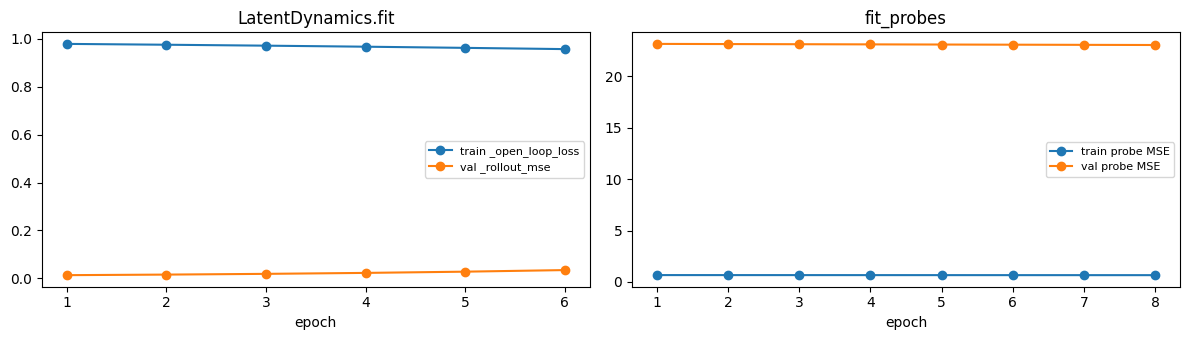

In [6]:
latent_record = json.loads((ARTIFACT_DIR / "latent.json").read_text())
probe_record = json.loads((ARTIFACT_DIR / "probes.json").read_text())
latent_curve = pd.DataFrame(latent_record["curve"])
probe_curve = pd.DataFrame(probe_record["curve"])
print(
    "latent best_epoch", latent_record["best_epoch"],
    "stopped_early", latent_record["stopped_early"],
    "ema_tau", latent_record["ema_tau"],
)
print("probe best_epoch", probe_record["best_epoch"], "stopped_early", probe_record["stopped_early"])
display(latent_curve)
display(probe_curve)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(latent_curve["epoch"], latent_curve["train_loss"], marker="o", label="train _open_loop_loss")
axes[0].plot(latent_curve["epoch"], latent_curve["val_loss"], marker="o", label="val _rollout_mse")
axes[0].set_title("LatentDynamics.fit")
axes[0].set_xlabel("epoch")
axes[0].legend(fontsize=8)
axes[1].plot(probe_curve["epoch"], probe_curve["train_loss"], marker="o", label="train probe MSE")
axes[1].plot(probe_curve["epoch"], probe_curve["val_loss"], marker="o", label="val probe MSE")
axes[1].set_title("fit_probes")
axes[1].set_xlabel("epoch")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()


## 5 · What the planner imagines on a held-out row

`open_rollout` is the unroll inside `_score`. This cell starts it from the first row of one validation SKU and steps it with that row's logged `filled_qty`, for `model_unroll_steps` steps. The solid lines are the log. The dashed lines are the probe's decoding. Cash is not re-encoded after the first step.


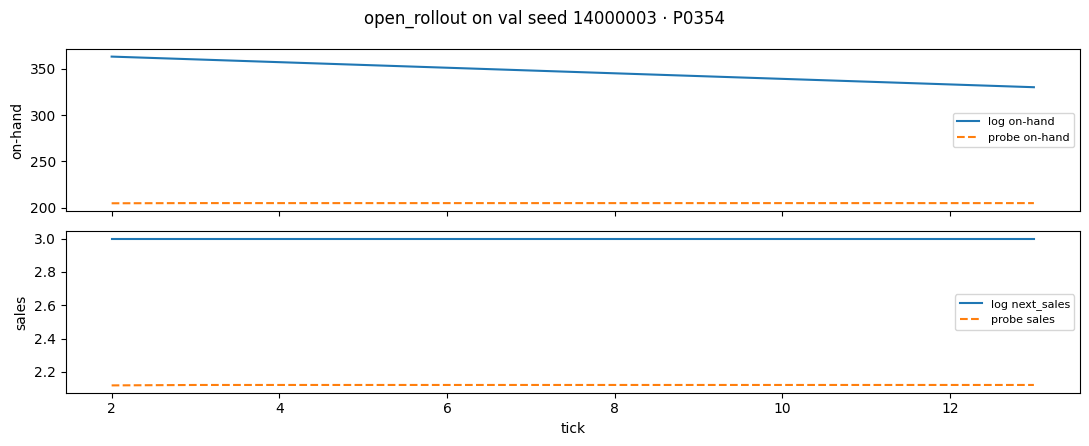

In [7]:
val_seed = sorted(dynamics.val_episodes)[0]
val_rows = frame.loc[frame["episode_seed"] == val_seed].sort_values(["product_id", "tick"])
val_pid = sorted(val_rows["product_id"].unique())[0]
group = val_rows[val_rows["product_id"] == val_pid].reset_index(drop=True)
horizon = dynamics.model_unroll_steps
start = log_row_features(group.iloc[0].to_dict(), delivery_lag=dynamics.delivery_lag)
rollout = dynamics.open_rollout([start])
predicted = []
for step in range(horizon):
    granted = float(group.iloc[step]["filled_qty"])
    on_hand, _profile, sales = rollout.step([granted])[0]
    predicted.append(
        {
            "tick": int(group.iloc[step + 1]["tick"]),
            "on_hand": on_hand,
            "sales": sales,
            "true_on_hand": int(group.iloc[step + 1]["on_hand"]),
            "true_sales": float(group.iloc[step]["next_sales"]),
        }
    )
predicted = pd.DataFrame(predicted)

fig, axes = plt.subplots(2, 1, figsize=(11, 4.5), sharex=True)
axes[0].plot(predicted["tick"], predicted["true_on_hand"], label="log on-hand")
axes[0].plot(predicted["tick"], predicted["on_hand"], ls="--", label="probe on-hand")
axes[0].legend(fontsize=8)
axes[0].set_ylabel("on-hand")
axes[1].plot(predicted["tick"], predicted["true_sales"], label="log next_sales")
axes[1].plot(predicted["tick"], predicted["sales"], ls="--", label="probe sales")
axes[1].legend(fontsize=8)
axes[1].set_xlabel("tick")
axes[1].set_ylabel("sales")
fig.suptitle(f"open_rollout on val seed {val_seed} · {val_pid}")
fig.tight_layout()
plt.show()


## 6 · Decisions on each validation episode

The holdout is `dynamics.val_episodes`, the split `LatentDynamics.fit` stored. Change `SHOW_SEEDS` to a subset. `None` plots every validation seed.

**Same state.** `SideBySide` is not a study policy. The shop runs the logged buyer (`log_buyer`), so the world is the training sequence. At each tick it also calls `ReplenishmentPlanner.decide` and `OrderUpToPolicy.decide` on that observation. Those two calls do not change the order the runner applies. A fresh planner comes from `retarget`, which keeps the weights and clears `sales_log`.

**Closed loop.** `run_policy_episode` attaches only node `S` and rolls the episode out. The chart uses a second `Runner` with that same override. Factories stay on the scenario default (`policy is None` produces `capacity_per_tick`), which is the eval path, not `_factory_overrides`.

The anchor is `order_up_to_from_params` on the holding-rate 0.01 `best_params`. If `runs/jepa-replenishment/tuning/order_up_to_holding_0_01/study.json` exists, `_order_up_to_factory` loads it instead.


anchor from runs/jepa-replenishment/tuning/order_up_to_holding_0_01/study.json


val seed 14000003 logged behavior periodic_reorder
censored rate at the last decide, _estimate_rate on the planner sales_log:
  P0354 rate 3.0000 cover targets {0: 0, 1: 9, 2: 18, 4: 36}
  P0549 rate 10.0000 cover targets {0: 0, 1: 30, 2: 60, 4: 120}


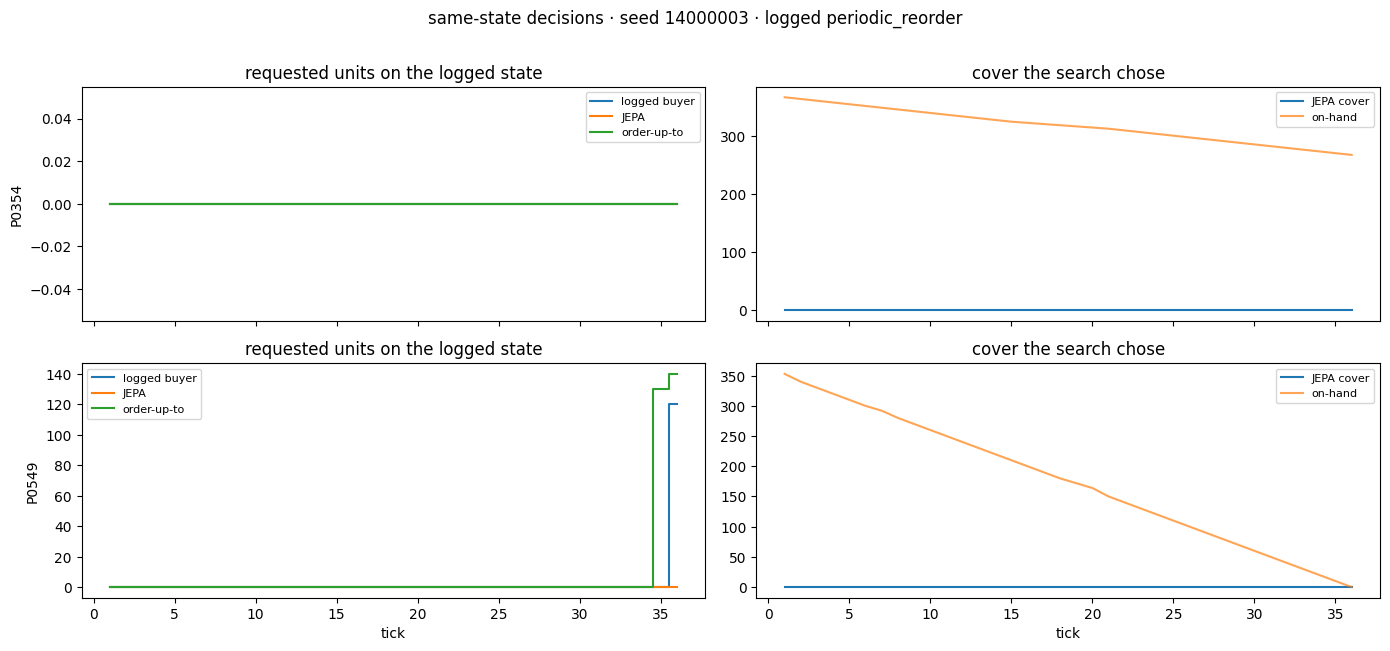

seed 14000003 closed loop  JEPA net_profit/initial_cash 17.3825  order_volume 0.0  stockout 0.000
seed 14000003 closed loop  order-up-to net_profit/initial_cash 11.9278  order_volume 130.0  stockout 0.000


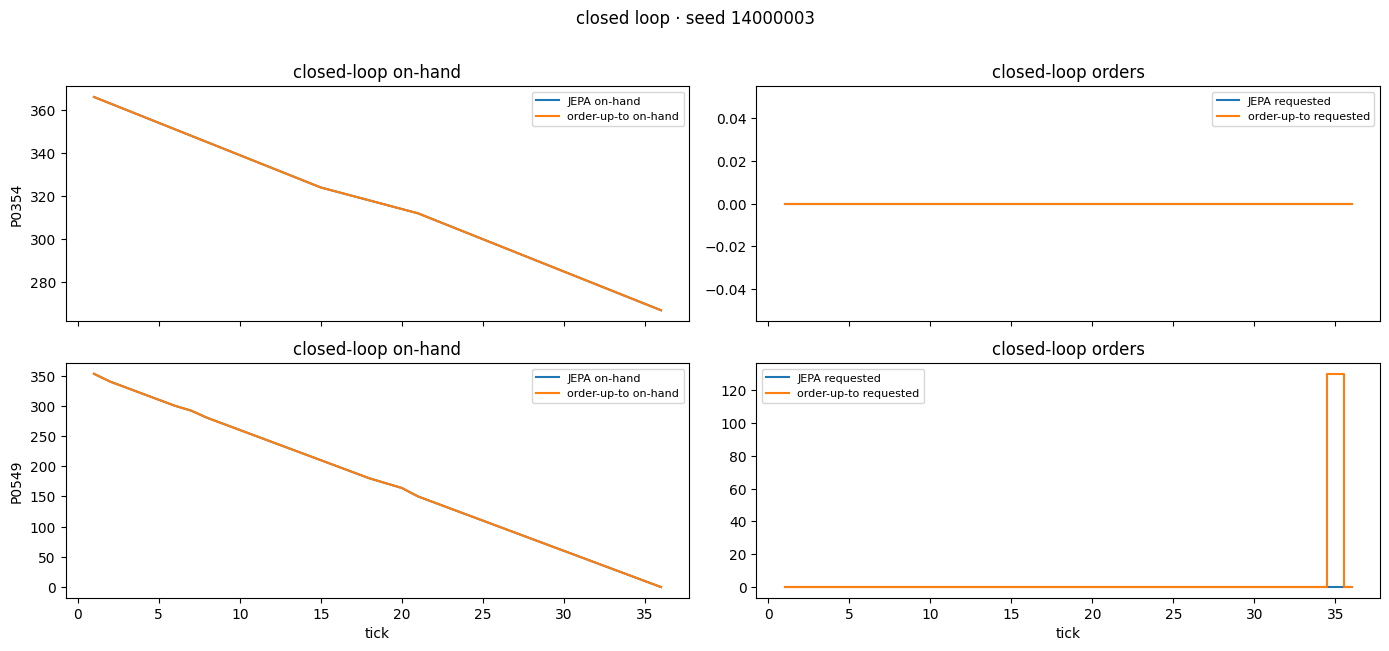

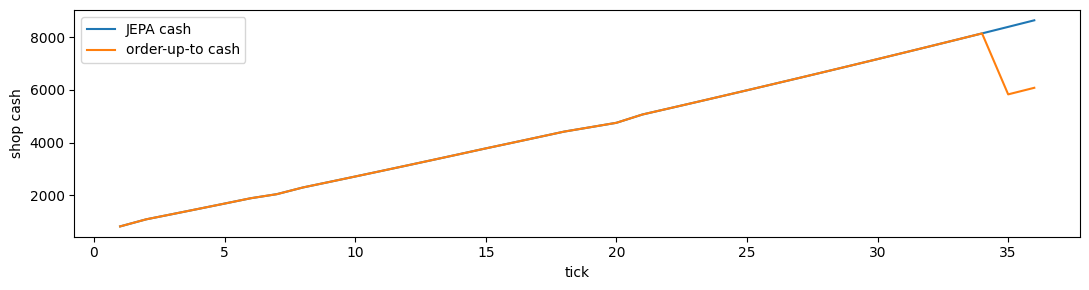

val seed 14000004 logged behavior exploratory
censored rate at the last decide, _estimate_rate on the planner sales_log:
  P0515 rate 2.3333 cover targets {0: 0, 1: 7, 2: 14, 4: 28}
  P0602 rate 10.0000 cover targets {0: 0, 1: 30, 2: 60, 4: 120}


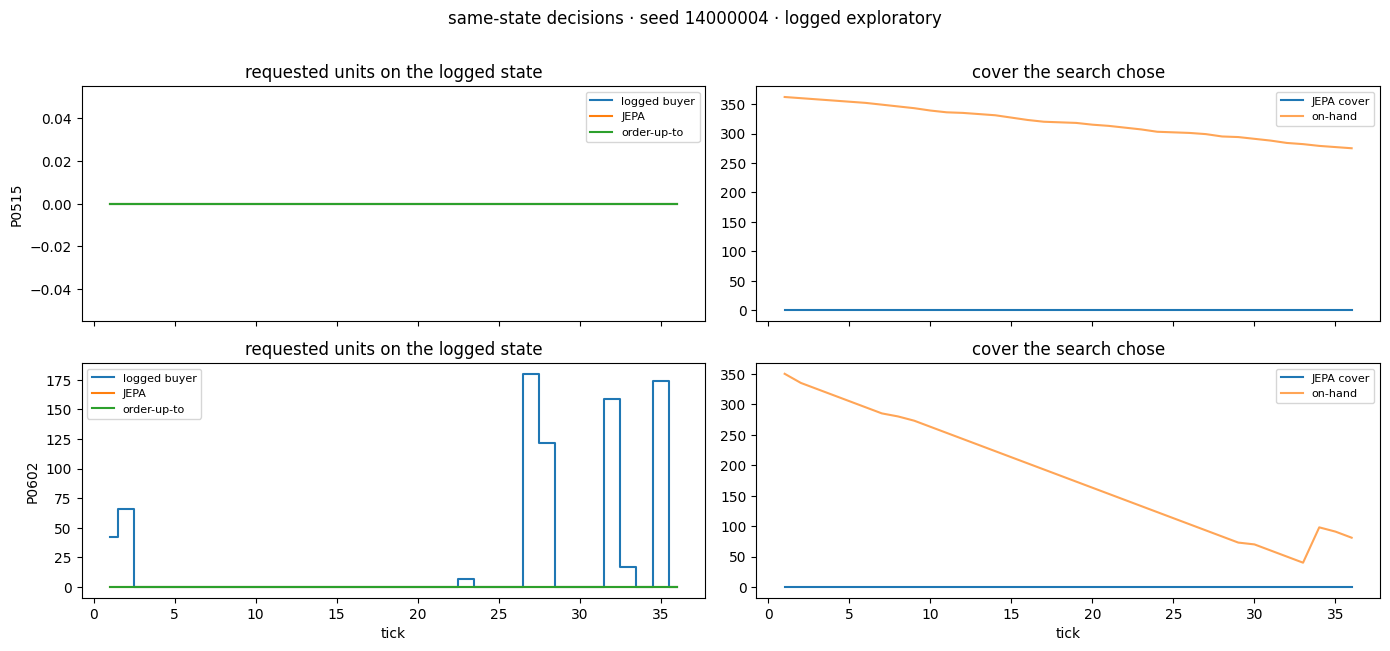

seed 14000004 closed loop  JEPA net_profit/initial_cash 22.9385  order_volume 0.0  stockout 0.000
seed 14000004 closed loop  order-up-to net_profit/initial_cash 18.2026  order_volume 125.0  stockout 0.000


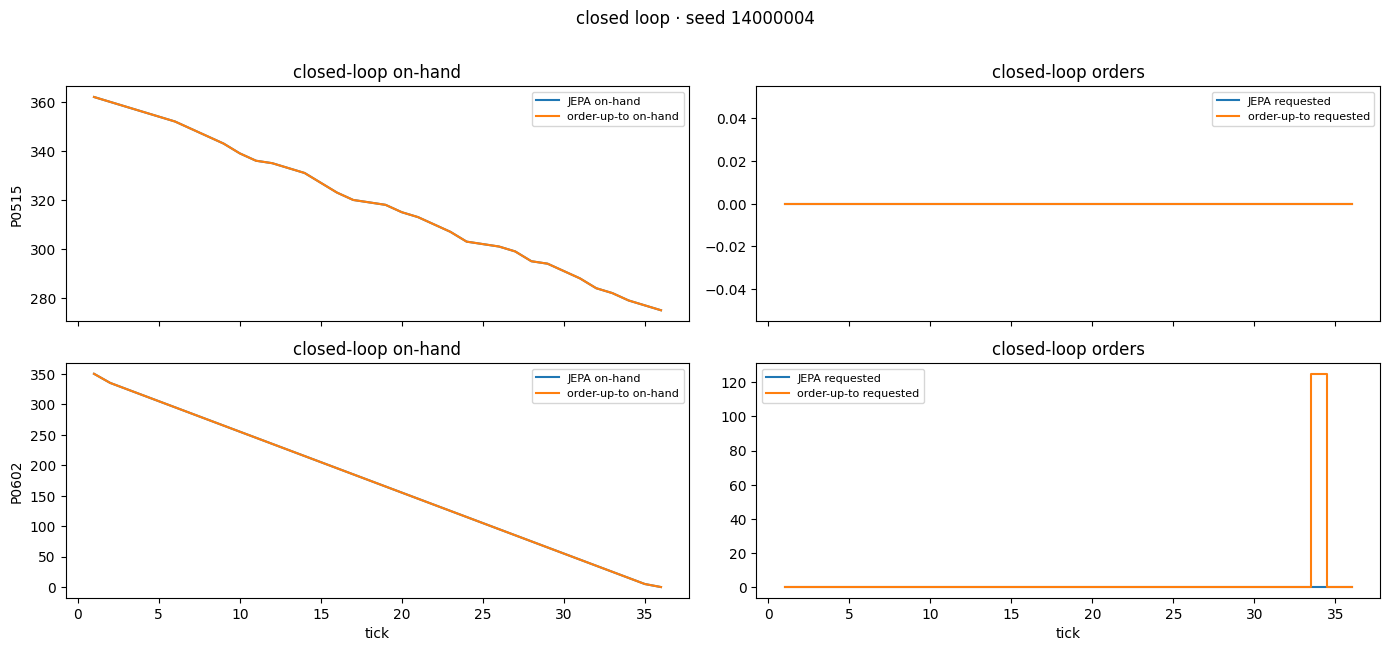

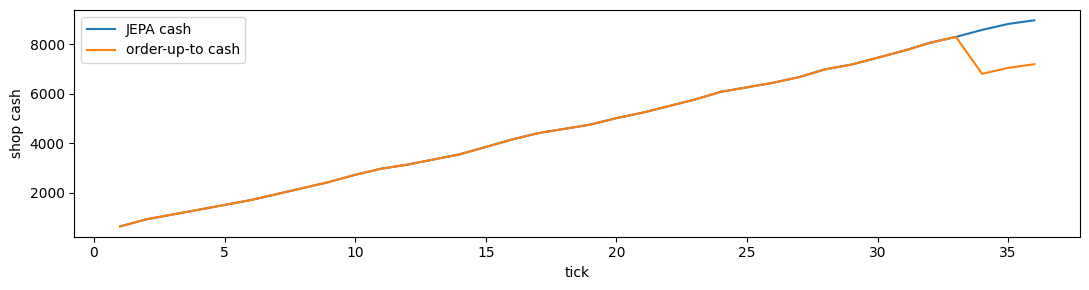

val seed 14000007 logged behavior over_order
censored rate at the last decide, _estimate_rate on the planner sales_log:
  P0464 rate 0.0000 cover targets {0: 0, 1: 0, 2: 0, 4: 0}
  P0744 rate 1.0000 cover targets {0: 0, 1: 3, 2: 6, 4: 12}


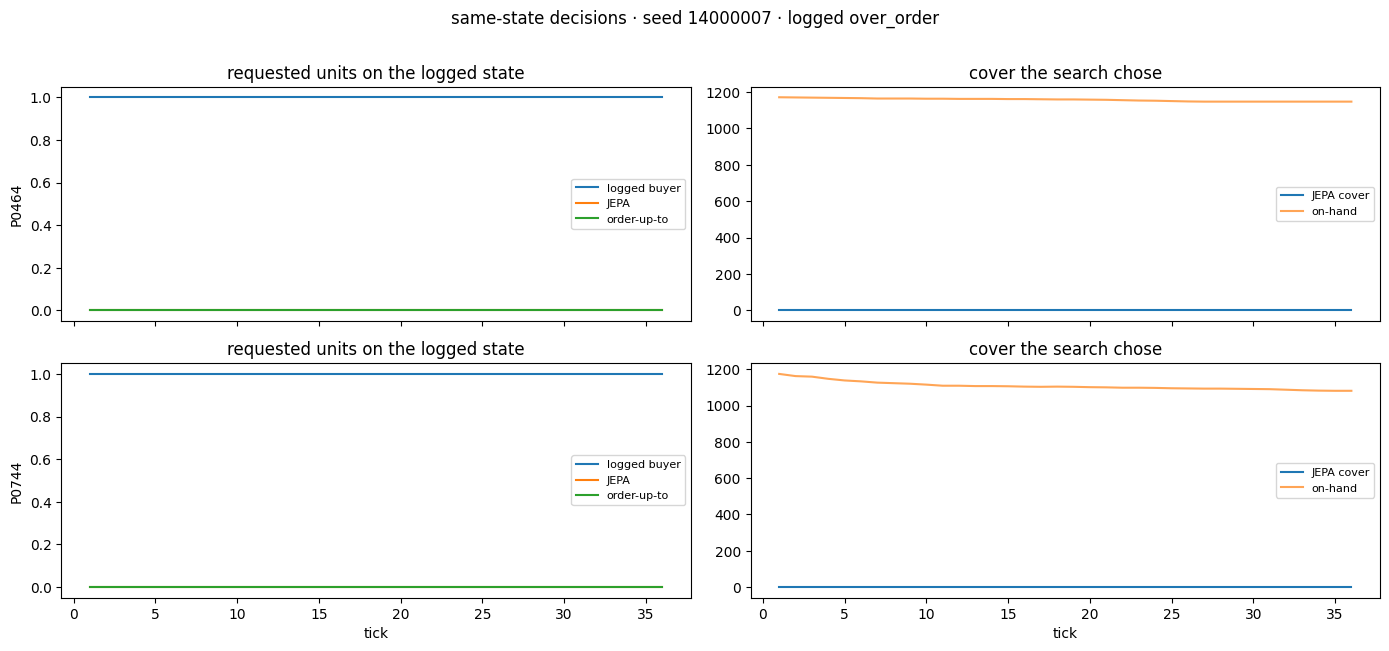

seed 14000007 closed loop  JEPA net_profit/initial_cash -3.8499  order_volume 0.0  stockout 0.000
seed 14000007 closed loop  order-up-to net_profit/initial_cash -3.8499  order_volume 0.0  stockout 0.000


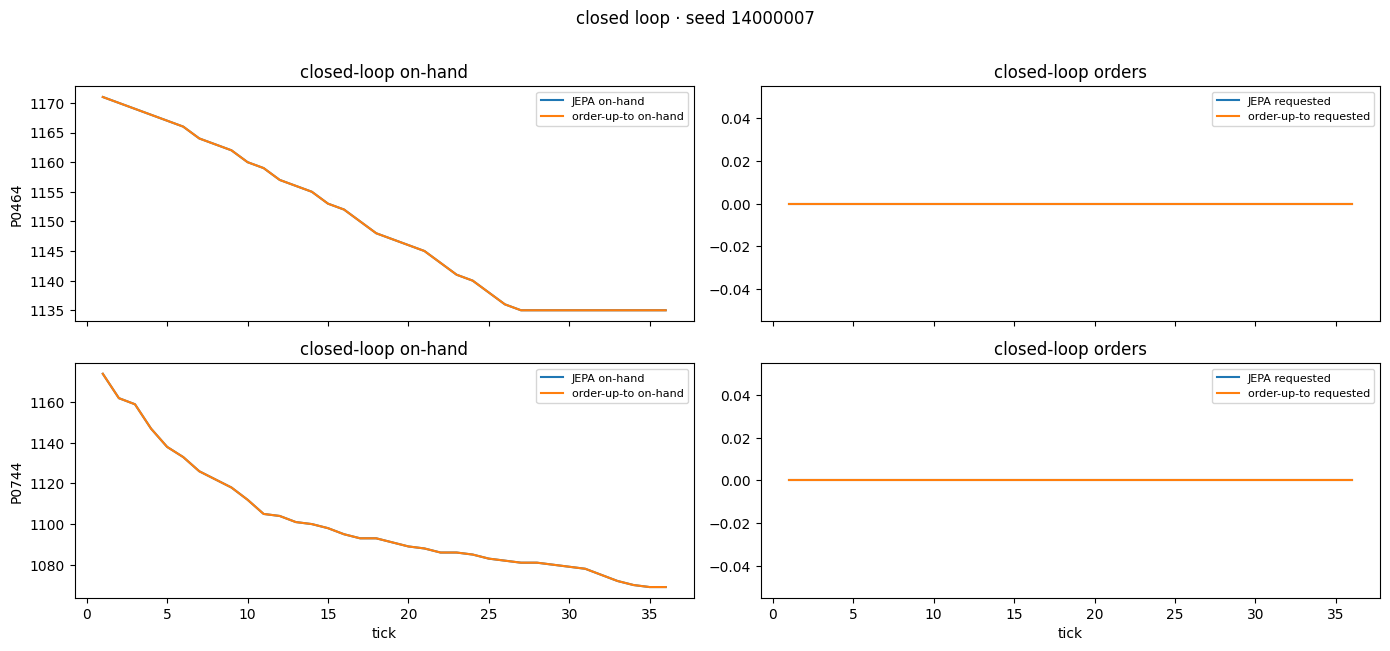

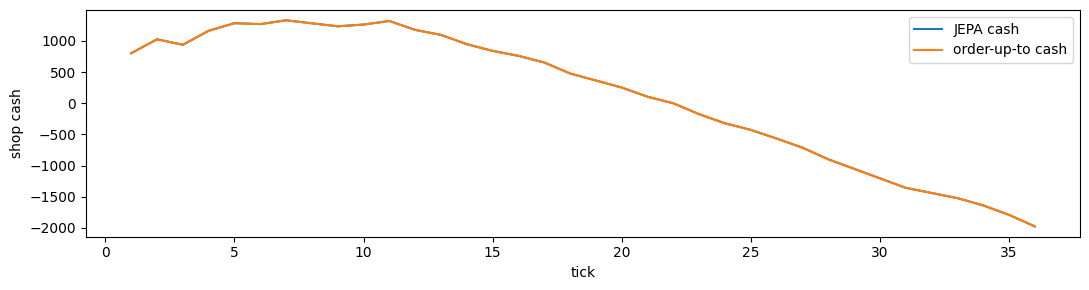

In [8]:
study_dir = Path("runs/jepa-replenishment/tuning") / order_up_to_study_name(IN_DISTRIBUTION_HOLDING_RATE)
if (study_dir / "study.json").is_file():
    anchor_factory = _order_up_to_factory(study_dir, IN_DISTRIBUTION_HOLDING_RATE)
    print("anchor from", study_dir / "study.json")
else:
    def anchor_factory():
        return order_up_to_from_params(PUBLISHED_ANCHOR_001)

    print("anchor from docs/jepa-replenishment.md best_params", PUBLISHED_ANCHOR_001)


class SideBySide(IntermediatePolicy):
    """Logged buyer drives the world. JEPA and the anchor decide on the same obs."""

    def __init__(self, logged, jepa, anchor):
        super().__init__(policy_seed=getattr(logged, "policy_seed", None))
        self.logged = logged
        self.jepa = jepa
        self.anchor = anchor
        self.rows = []

    def decide(self, obs, table):
        logged_action = self.logged.decide(obs, table)
        jepa_action = self.jepa.decide(obs, table)
        anchor_action = self.anchor.decide(obs, table)
        tick = int(obs.get("tick") or 0)
        inventory = dict(obs.get("inventory") or {})
        chosen = self.jepa.proposals[-1]["chosen"]
        for pid in inventory:
            self.rows.append(
                {
                    "tick": tick,
                    "product_id": pid,
                    "on_hand": int(inventory[pid]),
                    "logged_requested": order_units(logged_action, pid),
                    "jepa_requested": order_units(jepa_action, pid),
                    "anchor_requested": order_units(anchor_action, pid),
                    "jepa_cover": int(chosen["covers"].get(pid, 0)),
                    "jepa_score": self.jepa.proposals[-1]["score"],
                }
            )
        return logged_action


def decisions_on_logged_episode(seed):
    seed = int(seed)
    behavior = frame.loc[frame["episode_seed"] == seed, "behavior"].iloc[0]
    spec = build_log_scenario(config, seed, catalog)
    logged, hyper = log_buyer(behavior, seed, spec.delivery_lag)
    jepa = planner.retarget(planner.holding_rate)
    viewer = SideBySide(logged, jepa, anchor_factory())
    overrides = _factory_overrides(spec.scenario)
    overrides["S"] = viewer
    Runner(spec.scenario, policy_overrides=overrides).run()
    rates = _estimate_rate(
        {pid: jepa.sales_log[pid] for pid in jepa.sales_log},
        max(1, jepa.delivery_lag),
        {pid: [] for pid in jepa.sales_log},
    )
    return behavior, hyper, pd.DataFrame(viewer.rows), rates


def plot_same_state(seed):
    behavior, hyper, decisions, rates = decisions_on_logged_episode(seed)
    print(f"val seed {seed} logged behavior {behavior}")
    print("censored rate at the last decide, _estimate_rate on the planner sales_log:")
    for pid, rate in sorted(rates.items()):
        targets = {
            cover: round(int(cover) * float(rate) * planner.delivery_lag) for cover in COVERS
        }
        print(f"  {pid} rate {rate:.4f} cover targets {targets}")
    pids = sorted(decisions["product_id"].unique())
    fig, axes = plt.subplots(len(pids), 2, figsize=(14, 3.2 * len(pids)), sharex=True, squeeze=False)
    for row_i, pid in enumerate(pids):
        sku = decisions[decisions["product_id"] == pid]
        ax = axes[row_i, 0]
        ax.step(sku["tick"], sku["logged_requested"], where="mid", label="logged buyer")
        ax.step(sku["tick"], sku["jepa_requested"], where="mid", label="JEPA")
        ax.step(sku["tick"], sku["anchor_requested"], where="mid", label="order-up-to")
        ax.set_ylabel(pid)
        ax.legend(fontsize=8)
        ax.set_title("requested units on the logged state")
        ax = axes[row_i, 1]
        ax.step(sku["tick"], sku["jepa_cover"], where="mid", label="JEPA cover")
        ax.plot(sku["tick"], sku["on_hand"], label="on-hand", alpha=0.7)
        ax.legend(fontsize=8)
        ax.set_title("cover the search chose")
    for ax in axes[-1]:
        ax.set_xlabel("tick")
    fig.suptitle(f"same-state decisions · seed {seed} · logged {behavior}", y=1.01)
    fig.tight_layout()
    plt.show()
    return decisions


def closed_loop(seed, factory):
    """Score with ``run_policy_episode``, then chart a fresh policy on a fresh scenario."""
    spec = build_log_scenario(config, int(seed), catalog)
    metrics = run_policy_episode(factory(), spec)
    spec = build_log_scenario(config, int(seed), catalog)
    run_log = Runner(spec.scenario, policy_overrides={"S": factory()}).run()
    shop = per_product_df(run_log, spec.scenario, "S")
    cash = node_timeseries_df(run_log, spec.scenario)
    cash = cash[cash["node_id"] == "S"]
    return metrics, shop, cash, float(spec.balance)


def plot_closed_loop(seed):
    jepa_metrics, jepa_shop, jepa_cash, balance = closed_loop(
        seed, lambda: planner.retarget(planner.holding_rate)
    )
    anchor_metrics, anchor_shop, anchor_cash, _balance = closed_loop(seed, anchor_factory)
    print(
        f"seed {seed} closed loop  "
        f"JEPA net_profit/initial_cash {jepa_metrics['net_profit'] / max(1e-9, balance):.4f}  "
        f"order_volume {jepa_metrics['order_volume']:.1f}  "
        f"stockout {jepa_metrics['stockout_rate']:.3f}"
    )
    print(
        f"seed {seed} closed loop  "
        f"order-up-to net_profit/initial_cash {anchor_metrics['net_profit'] / max(1e-9, balance):.4f}  "
        f"order_volume {anchor_metrics['order_volume']:.1f}  "
        f"stockout {anchor_metrics['stockout_rate']:.3f}"
    )
    pids = sorted(set(jepa_shop["pid"]).union(anchor_shop["pid"]))
    fig, axes = plt.subplots(len(pids), 2, figsize=(14, 3.2 * len(pids)), sharex=True, squeeze=False)
    for row_i, pid in enumerate(pids):
        left = jepa_shop[jepa_shop["pid"] == pid]
        right = anchor_shop[anchor_shop["pid"] == pid]
        ax = axes[row_i, 0]
        ax.plot(left["tick"], left["inventory"], label="JEPA on-hand")
        ax.plot(right["tick"], right["inventory"], label="order-up-to on-hand")
        ax.set_ylabel(pid)
        ax.legend(fontsize=8)
        ax.set_title("closed-loop on-hand")
        ax = axes[row_i, 1]
        ax.step(left["tick"], left["orders"], where="mid", label="JEPA requested")
        ax.step(right["tick"], right["orders"], where="mid", label="order-up-to requested")
        ax.legend(fontsize=8)
        ax.set_title("closed-loop orders")
    for ax in axes[-1]:
        ax.set_xlabel("tick")
    fig.suptitle(f"closed loop · seed {seed}", y=1.01)
    fig.tight_layout()
    plt.show()

    fig, ax = plt.subplots(figsize=(11, 3))
    ax.plot(jepa_cash["tick"], jepa_cash["cash"], label="JEPA cash")
    ax.plot(anchor_cash["tick"], anchor_cash["cash"], label="order-up-to cash")
    ax.legend()
    ax.set_xlabel("tick")
    ax.set_ylabel("shop cash")
    fig.tight_layout()
    plt.show()


SHOW_SEEDS = None
seeds = sorted(dynamics.val_episodes) if SHOW_SEEDS is None else list(SHOW_SEEDS)
for seed in seeds:
    plot_same_state(seed)
    plot_closed_loop(seed)


## What this short run is showing

On the executed 36-tick log, `fill_rate` is about 0.039 and every closed-loop JEPA `order_volume` is 0. On two validation seeds that empty order earns more `net_profit / initial_cash` than the tuned order-up-to rule, and stockout rate is 0 for both. The third seed orders nothing on both sides.

That happens because the window is shorter than a replenishment cycle. The sampled textbook arms in this log place no positive request, so `_fill_ratio` falls through to every positive request, which is the over-order arm. The planner then imagines a grant that barely arrives, `_score` picks cover 0, and the anchor's purchases are a cost inside a window that never stocks out.

The published comparison is 365 ticks. There the tuned order-up-to rule earns about 1.021 and the latent planner about 0.381. Raising `DRILL_TICKS` toward that length is what makes buying necessary. The charts above are the 36-tick mechanism, not that year-long table.
